### Name : Muhammad Saad
### Reg.No : SP24-BSE-081
### Section : SP24-BSE-C

Imports for the following labs

In [35]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import train_test_split
from sklearn.linear_model import LinearRegression,LogisticRegression
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder
import math

### Activity 1: (Linear Regression)

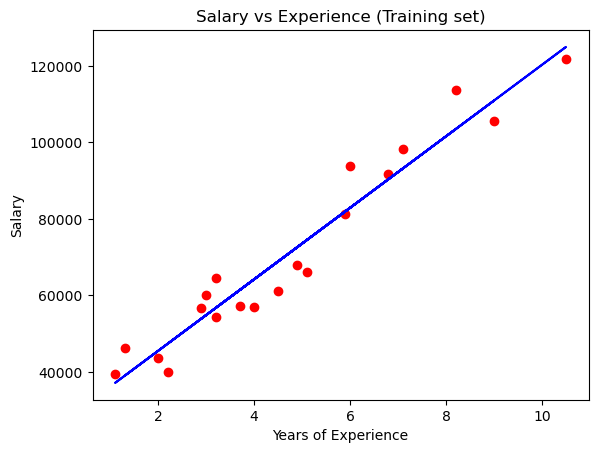

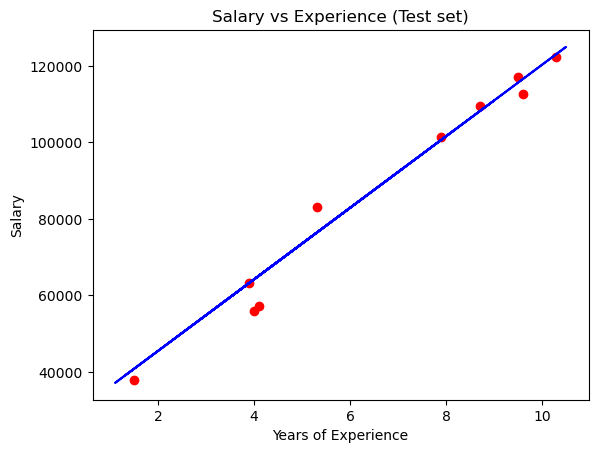

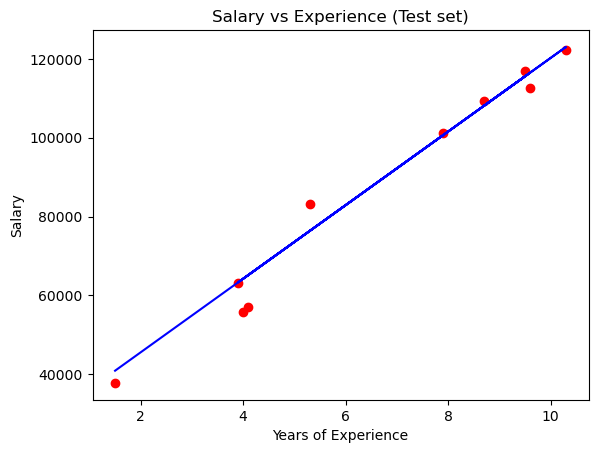

[138967.5015615]
Coefficient is: [9345.94244312]
Slope/Intercept: 26816.192244031183
Manual prediction by using coefficient and intercept 167005.32889083118
autoprediction: [167005.32889087]


In [7]:

"""## Importing the dataset"""
dataset = pd.read_csv("/home/saadm/University/6th Semester/ML-Sir Qaiser Habib/Lab 2/Salary_Data.csv")
X = dataset.iloc[:,:-1].values
y = dataset.iloc[:,-1].values
"""## Splitting the dataset into the Training set and Test set"""
X_train , X_test , y_train , y_test = train_test_split(X,y,test_size = 1/3 ,
random_state = 0)
""" Training the Simple Linear Regression model on the Training set"""
regressor = LinearRegression()
regressor.fit(X_train,y_train)
""" Predicting the Test set results"""
# X_test = np.array([X_test])
# print(X_test)
y_pred = regressor.predict(X_test)
"""## Visualising the Training set results"""
plt.scatter(X_train,y_train,color='r')
plt.plot(X_train , regressor.predict(X_train),color='b')
plt.title('Salary vs Experience (Training set)')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.show()
""" Visualising the Test set results"""
plt.scatter(X_test, y_test, color = 'red')
plt.plot(X_train, regressor.predict(X_train), color = 'blue')
plt.title('Salary vs Experience (Test set)')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.show()
""" Visualizing Test Results by using X_test and y_pred in plt.plot"""
plt.scatter(X_test, y_test, color = 'red')
plt.plot(X_test, y_pred, color = 'blue')
plt.title('Salary vs Experience (Test set)')
plt.xlabel('Years of Experience')
plt.ylabel('Salary')
plt.show()
""" Making a single prediction (for example the salary of an employee with 12
years of experience)"""
single_prediction = regressor.predict([[12]])
print (single_prediction)
coefficient = regressor.coef_
intercept = regressor.intercept_
print ("Coefficient is:",coefficient)
print("Slope/Intercept:" , intercept)
""" Extra Practice"""
manual_prediction = 26816.192244031183 + 9345.94244312*15
print ("Manual prediction by using coefficient and intercept" ,
manual_prediction)
auto_prediction = regressor.predict([[15]])
print("autoprediction:",auto_prediction)

### Activity 2: (Multiple Linear Regression)

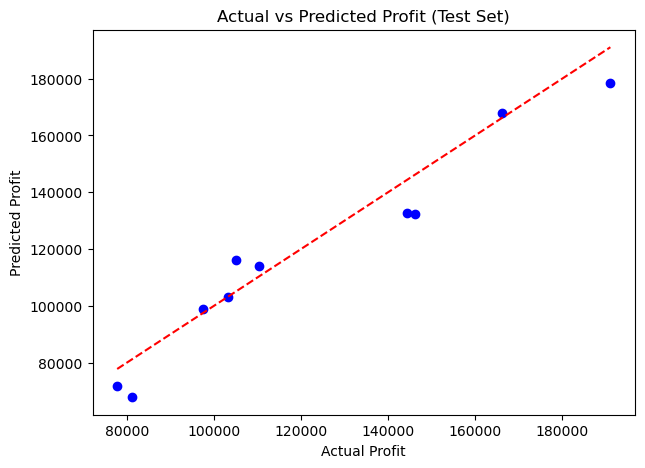

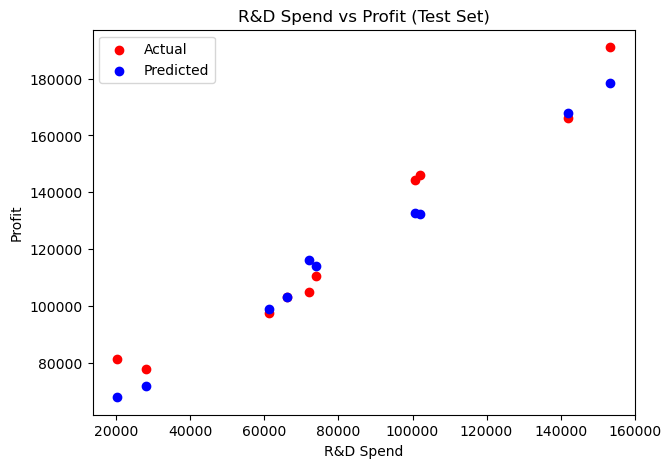

In [30]:
"""## Importing the dataset"""
dataset = pd.read_csv('/home/saadm/University/6th Semester/ML-Sir Qaiser Habib/Lab 2/50_Startups_dataset.csv')
X = dataset.iloc[:, 1:-1].values   # skip the index column (first) and Profit (last)
y = dataset.iloc[:, -1].values
# print(X)

"""## Encoding categorical data"""
ct = ColumnTransformer(transformers=[('encoder', OneHotEncoder(), [3])],
                       remainder='passthrough')
X = np.array(ct.fit_transform(X))
# print(X)

"""## Splitting the dataset into the Training set and Test set"""
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2,
                                                    random_state=0)

"""## Training the Multiple Linear Regression model on the Training set"""
regressor = LinearRegression()
regressor.fit(X_train, y_train)

"""## Predicting the Test set results"""
y_pred = regressor.predict(X_test)
np.set_printoptions(precision=2)
# print(np.concatenate((y_pred.reshape(len(y_pred), 1),
#                       y_test.reshape(len(y_test), 1)), 1))
# Actual vs predicted profit
plt.figure(figsize=(7, 5))
plt.scatter(y_test, y_pred, color='blue')
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], color='red', linestyle='--')  # perfect-prediction line
plt.xlabel('Actual Profit')
plt.ylabel('Predicted Profit')
plt.title('Actual vs Predicted Profit (Test Set)')
plt.show()

# R&D Spend vs Profit (column 3 after encoding = R&D Spend)
plt.figure(figsize=(7, 5))
plt.scatter(X_test[:, 3], y_test, color='red', label='Actual')
plt.scatter(X_test[:, 3], y_pred, color='blue', label='Predicted')
plt.xlabel('R&D Spend')
plt.ylabel('Profit')
plt.title('R&D Spend vs Profit (Test Set)')
plt.legend()
plt.show()

### Activity 3

   age  bought_insurance
0   22                 0
1   25                 0
2   47                 1
3   52                 0
4   46                 1


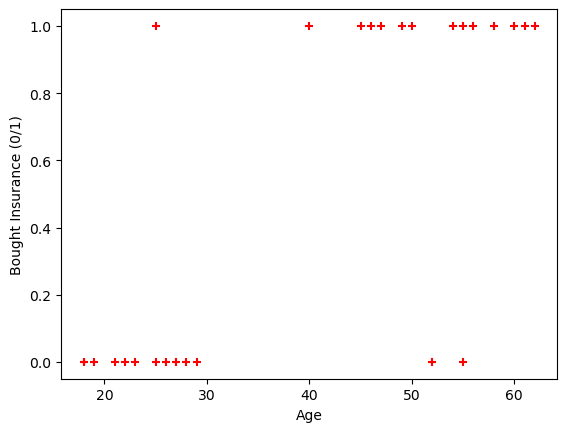

Predictions: [1 1 1 1 1 0]
Probabilities [no, yes]:
 [[0.34 0.66]
 [0.27 0.73]
 [0.29 0.71]
 [0.13 0.87]
 [0.16 0.84]
 [0.81 0.19]]
Accuracy: 1.0
m = 0.11216015594818113  b = -4.609606842692202
Age 35: P(buy) = 0.335 -> does not buy
Age 43: P(buy) = 0.553 -> buys


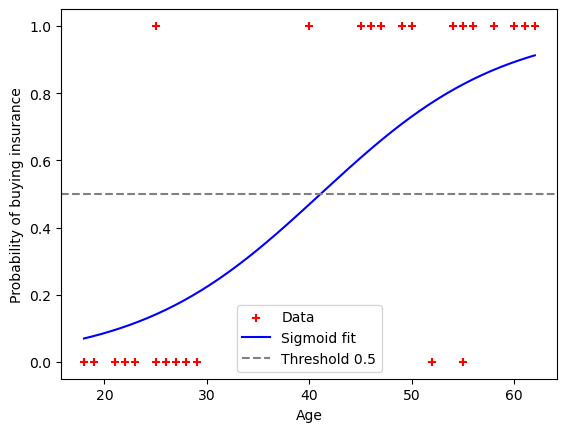

In [36]:


# If using Colab:
# from google.colab import drive
# drive.mount('/content/gdrive')
# df = pd.read_csv("/content/gdrive/My Drive/insurance_data.csv")
df = pd.read_csv("/home/saadm/University/6th Semester/ML-Sir Qaiser Habib/Lab 2/insurance_data.csv")   # change to your path
print(df.head())

# Visualize raw data
plt.scatter(df.age, df.bought_insurance, marker='+', color='red')
plt.xlabel('Age')
plt.ylabel('Bought Insurance (0/1)')
plt.show()

# Split
X_train, X_test, y_train, y_test = train_test_split(
    df[['age']], df.bought_insurance, train_size=0.8, random_state=0)

# Train
model = LogisticRegression()
model.fit(X_train, y_train)

# Predict
y_predicted = model.predict(X_test)
print("Predictions:", y_predicted)
print("Probabilities [no, yes]:\n", model.predict_proba(X_test))
print("Accuracy:", model.score(X_test, y_test))

# Coefficients: z = m*x + b
m = model.coef_[0][0]
b = model.intercept_[0]
print("m =", m, " b =", b)

# Sigmoid from scratch
def sigmoid(x):
    return 1 / (1 + math.exp(-x))

def prediction_function(age):
    z = m * age + b
    return sigmoid(z)

for age in (35, 43):
    p = prediction_function(age)
    print(f"Age {age}: P(buy) = {p:.3f} ->", "buys" if p > 0.5 else "does not buy")

# Plot the fitted sigmoid curve over the data
ages = np.linspace(df.age.min(), df.age.max(), 200)
probs = [prediction_function(a) for a in ages]

plt.scatter(df.age, df.bought_insurance, marker='+', color='red', label='Data')
plt.plot(ages, probs, color='blue', label='Sigmoid fit')
plt.axhline(0.5, color='gray', linestyle='--', label='Threshold 0.5')
plt.xlabel('Age')
plt.ylabel('Probability of buying insurance')
plt.legend()
plt.show()